# OSM Campus Map Analysis

공공 지도 기반 캠퍼스 위치추정 단서의 가용성 탐색

단국대 죽전·천안·KAIST의 OSM 건물, POI, 보행 네트워크를 이용해 이름 정보의 분포와 교차로 서술자의 중복성을 분석합니다.

**범위:** 지도 데이터 분석이며 로봇 위치추정, OCR, SLAM, 센서 관측 실험을 구현하거나 평가하지 않았습니다.

**기존 출력:** 제공된 원본 노트북의 실행 결과를 보존했습니다. 정확한 수집 시각과 경계의 적합성은 미확인입니다. 그림의 blind spot/recognition/identifiable 표기는 각각 지도상 반경 내 이름 있는 대표점 부재/탐색 반경/서술자 유일성을 뜻하며 실제 가시성이나 위치추정 성공률을 뜻하지 않습니다.

데이터: © OpenStreetMap contributors. 출처: https://www.openstreetmap.org/copyright


In [2]:
# 원본 실행에서 확인한 OSMnx 버전
!pip install -q osmnx==2.1.1


In [3]:
import math
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import osmnx as ox

warnings.filterwarnings("ignore")
ox.settings.http_user_agent = "campus-osm-analysis (student project)"
ox.settings.requests_timeout = 180
print("osmnx", ox.__version__)

# ---- 설정 ----
CAMPUSES = {                       # 이름(그래프용 영문) : Nominatim 검색어
    "Dankook-Jukjeon": "단국대학교 죽전캠퍼스",
    "Dankook-Cheonan": "단국대학교 천안캠퍼스",
    "KAIST":           "한국과학기술원",
}
LANDMARK_RADIUS = 50   # m: 지도상 랜드마크 대표점 탐색 반경 (가시성 아님)
BUFFER = 30            # m: 캠퍼스 경계 바깥 도로도 조금 포함

osmnx 2.1.1


## 1. 데이터 수집

- `geocode_to_gdf`: Nominatim에서 캠퍼스 **경계 폴리곤**을 받음
- `features_from_polygon`: Overpass API로 경계 안의 건물/POI/실내 객체를 받음
- `graph_from_polygon`: 보행 네트워크(노드=교차로·끝점, 엣지=길)를 그래프로 받음

Overpass 기본 서버가 바쁘면 미러 서버로 자동 전환합니다.

In [4]:
OVERPASS_SERVERS = [
    "https://overpass-api.de/api",
    "https://maps.mail.ru/osm/tools/overpass/api",
    "https://overpass.kumi.systems/api",
]

def with_fallback(fn, *args, **kwargs):
    # Overpass 서버를 순서대로 시도
    last = None
    for url in OVERPASS_SERVERS:
        ox.settings.overpass_url = url
        ox.settings.overpass_rate_limit = (url == OVERPASS_SERVERS[0])
        try:
            return fn(*args, **kwargs)
        except ox._errors.InsufficientResponseError:
            raise                      # 서버는 정상, 해당 객체가 없을 뿐
        except Exception as e:
            print(f"  ! {url} 실패 ({type(e).__name__}) -> 다음 서버")
            last = e
    raise last

def get_features(poly, tags):
    try:
        return with_fallback(ox.features_from_polygon, poly, tags)
    except ox._errors.InsufficientResponseError:
        return None

LANDMARK_TAGS = {"amenity": True, "shop": True, "tourism": True,
                 "leisure": True, "office": True, "historic": True}

data = {}
for name, query in CAMPUSES.items():
    print(f"[{name}] 수집 중...")
    boundary = ox.geocode_to_gdf(query)
    b_proj = ox.projection.project_gdf(boundary)          # 미터 단위 좌표계(UTM)
    crs = b_proj.crs
    poly_proj = b_proj.geometry.iloc[0].buffer(BUFFER)
    poly = ox.projection.project_geometry(poly_proj, crs=crs, to_latlong=True)[0]

    # 건물·POI·실내 객체를 한 번의 쿼리로 받은 뒤 나눔 (서버 요청 수 최소화)
    allf = get_features(poly, {"building": True, "indoor": True, **LANDMARK_TAGS})
    def pick(cols):
        if allf is None:
            return None
        cols = [c for c in cols if c in allf.columns]
        sub = allf[allf[cols].notna().any(axis=1)] if cols else allf.iloc[0:0]
        return sub if len(sub) else None
    buildings = pick(["building"])
    pois = pick(list(LANDMARK_TAGS))
    if pois is not None and "building" in pois.columns:
        pois = pois[pois["building"].isna()]        # 건물과 중복되는 POI 제외
        pois = pois if len(pois) else None
    indoor = pick(["indoor"])
    G = with_fallback(ox.graph_from_polygon, poly, network_type="walk")

    data[name] = dict(
        boundary=b_proj, crs=crs,
        buildings=None if buildings is None else buildings.to_crs(crs),
        pois=None if pois is None else pois.to_crs(crs),
        indoor=indoor,
        G=ox.project_graph(G, to_crs=crs),
    )
    print(f"  건물 {0 if buildings is None else len(buildings)}개, "
          f"POI {0 if pois is None else len(pois)}개, 보행노드 {len(G.nodes)}개")

[Dankook-Jukjeon] 수집 중...
  건물 45개, POI 79개, 보행노드 189개
[Dankook-Cheonan] 수집 중...
  ! https://overpass-api.de/api 실패 (ResponseStatusCodeError) -> 다음 서버
  건물 22개, POI 10개, 보행노드 67개
[KAIST] 수집 중...
  ! https://overpass-api.de/api 실패 (ResponseStatusCodeError) -> 다음 서버
  건물 202개, POI 338개, 보행노드 1592개


## 2. 지도 기본 통계

로봇 입장에서 **이름(name)이 붙은 건물**은 안내판 텍스트와 매칭할 수 있는 단서입니다.
`addr:housenumber`(번지)나 `building:levels`(층수) 같은 속성도 위치추정에 쓸 수 있는 정보입니다.

In [5]:
def has(df, col):
    # 해당 태그가 채워진 객체 비율
    if df is None or col not in df.columns:
        return 0.0
    return df[col].notna().mean()

rows = []
for name, d in data.items():
    b, p, G = d["buildings"], d["pois"], d["G"]
    area_ha = d["boundary"].area.iloc[0] / 1e4
    nodes, edges = ox.graph_to_gdfs(ox.convert.to_undirected(G))
    deg = dict(ox.convert.to_undirected(G).degree())
    n_inter = sum(1 for v in deg.values() if v >= 3)
    nb = 0 if b is None else len(b)
    rows.append({
        "campus": name,
        "area (ha)": round(area_ha, 1),
        "buildings": nb,
        "buildings / ha": round(nb / area_ha, 2),
        "named buildings %": round(100 * has(b, "name"), 1),
        "has levels %": round(100 * has(b, "building:levels"), 1),
        "POIs": 0 if p is None else len(p),
        "named POIs %": round(100 * has(p, "name"), 1),
        "walk length (km)": round(edges["length"].sum() / 1000, 2),
        "intersections (deg>=3)": n_inter,
        "indoor objects": 0 if d["indoor"] is None else len(d["indoor"]),
    })
stats = pd.DataFrame(rows).set_index("campus")
stats

                 area (ha)  buildings  buildings / ha  named buildings %  \
campus                                                                     
Dankook-Jukjeon       47.1         45            0.95               93.3   
Dankook-Cheonan       27.8         22            0.79               86.4   
KAIST                113.8        202            1.77               55.0   

                 has levels %  POIs  named POIs %  walk length (km)  \
campus                                                                
Dankook-Jukjeon          66.7    79          62.0              9.66   
Dankook-Cheonan           0.0    10          70.0              6.40   
KAIST                    40.1   338          18.9             55.41   

                 intersections (deg>=3)  indoor objects  
campus                                                   
Dankook-Jukjeon                     117              30  
Dankook-Cheonan                      47               0  
KAIST                          

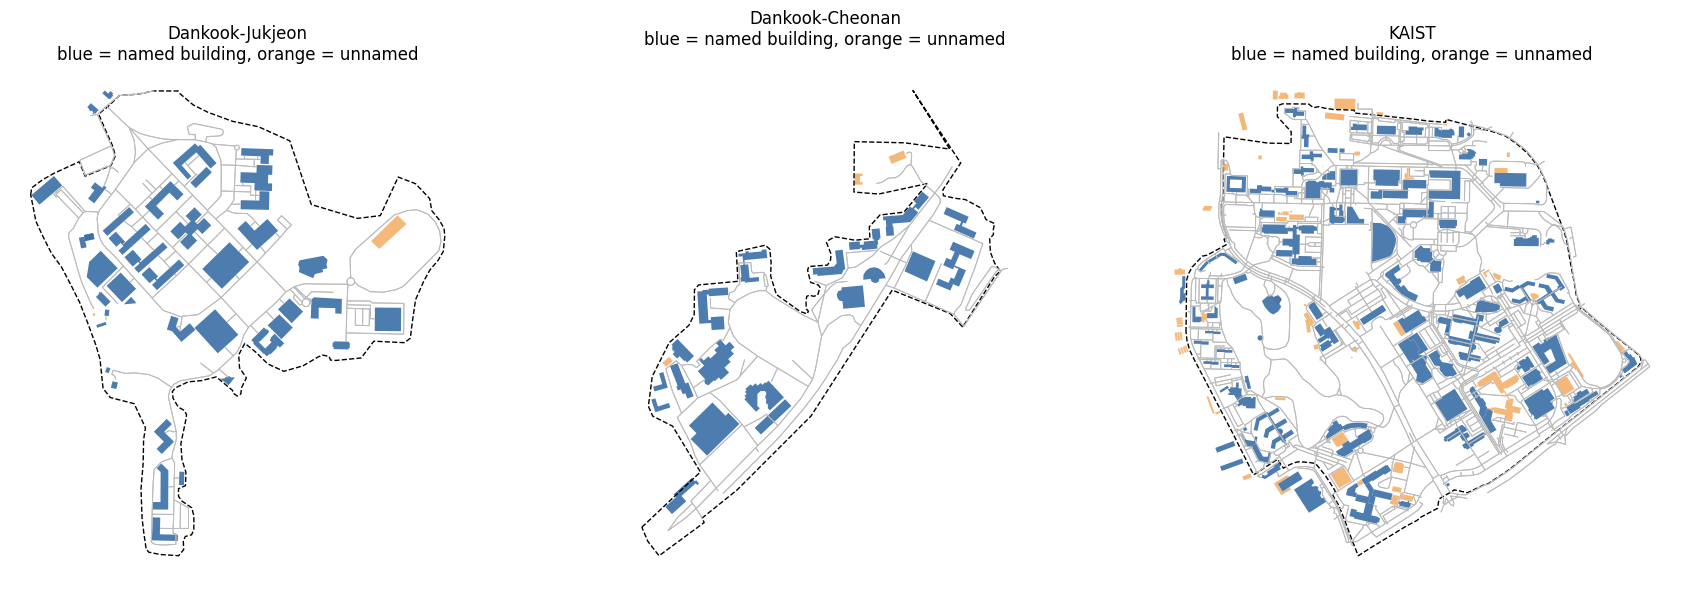

In [6]:
fig, axes = plt.subplots(1, len(data), figsize=(6 * len(data), 6))
for ax, (name, d) in zip(np.atleast_1d(axes), data.items()):
    d["boundary"].boundary.plot(ax=ax, color="k", lw=1, ls="--")
    _, e = ox.graph_to_gdfs(d["G"])
    e.plot(ax=ax, color="#bbbbbb", lw=0.7)
    b = d["buildings"]
    if b is not None:
        named = b["name"].notna() if "name" in b.columns else pd.Series(False, index=b.index)
        b[~named].plot(ax=ax, color="#f2a65a", alpha=0.8)
        b[named].plot(ax=ax, color="#3a6ea5", alpha=0.9)
    ax.set_title(f"{name}\nblue = named building, orange = unnamed")
    ax.set_axis_off()
plt.tight_layout(); plt.show()

## 3. 이름 있는 랜드마크 대표점의 근접성

보행 그래프 노드(교차로·끝점)에서 반경 내 이름 있는 건물·POI 대표점 수를 계산합니다. 대표점은 출입구나 간판 위치가 아닙니다.

0개는 해당 지도·반경 정의상 후보가 없다는 뜻입니다. 1개 이상이어도 가림, 시야, 이름 중복, 인식 실패 때문에 실제 위치추정이 가능하다는 뜻은 아닙니다. 노드 기반 비율은 보행로 길이 또는 캠퍼스 면적 비율이 아닙니다.


In [7]:
def named_landmarks(d):
    parts = []
    for key in ("buildings", "pois"):
        g = d[key]
        if g is not None and "name" in g.columns:
            parts.append(g[g["name"].notna()][["name", "geometry"]])
    if not parts:
        return None
    lm = pd.concat(parts)
    lm["geometry"] = lm.geometry.representative_point()   # 폴리곤 → 대표점
    return lm

coverage = {}
for name, d in data.items():
    nodes, _ = ox.graph_to_gdfs(d["G"])
    lm = named_landmarks(d)
    if lm is None or len(lm) == 0:
        counts = np.zeros(len(nodes), dtype=int)
    else:
        P = np.c_[nodes.geometry.x, nodes.geometry.y]           # (N,2) 노드 좌표
        L = np.c_[lm.geometry.x, lm.geometry.y]                 # (M,2) 랜드마크 좌표
        dist = np.linalg.norm(P[:, None, :] - L[None, :, :], axis=2)   # (N,M)
        counts = (dist <= LANDMARK_RADIUS).sum(axis=1)
    nodes = nodes.assign(n_landmarks=counts)
    coverage[name] = nodes
    print(f"{name:16s} 사각지대(0개) 비율: {100*(counts==0).mean():5.1f}%   "
          f"평균 랜드마크 수: {counts.mean():.2f}")

Dankook-Jukjeon  사각지대(0개) 비율:  14.8%   평균 랜드마크 수: 2.03
Dankook-Cheonan  사각지대(0개) 비율:  67.2%   평균 랜드마크 수: 0.36
KAIST            사각지대(0개) 비율:  31.8%   평균 랜드마크 수: 1.41


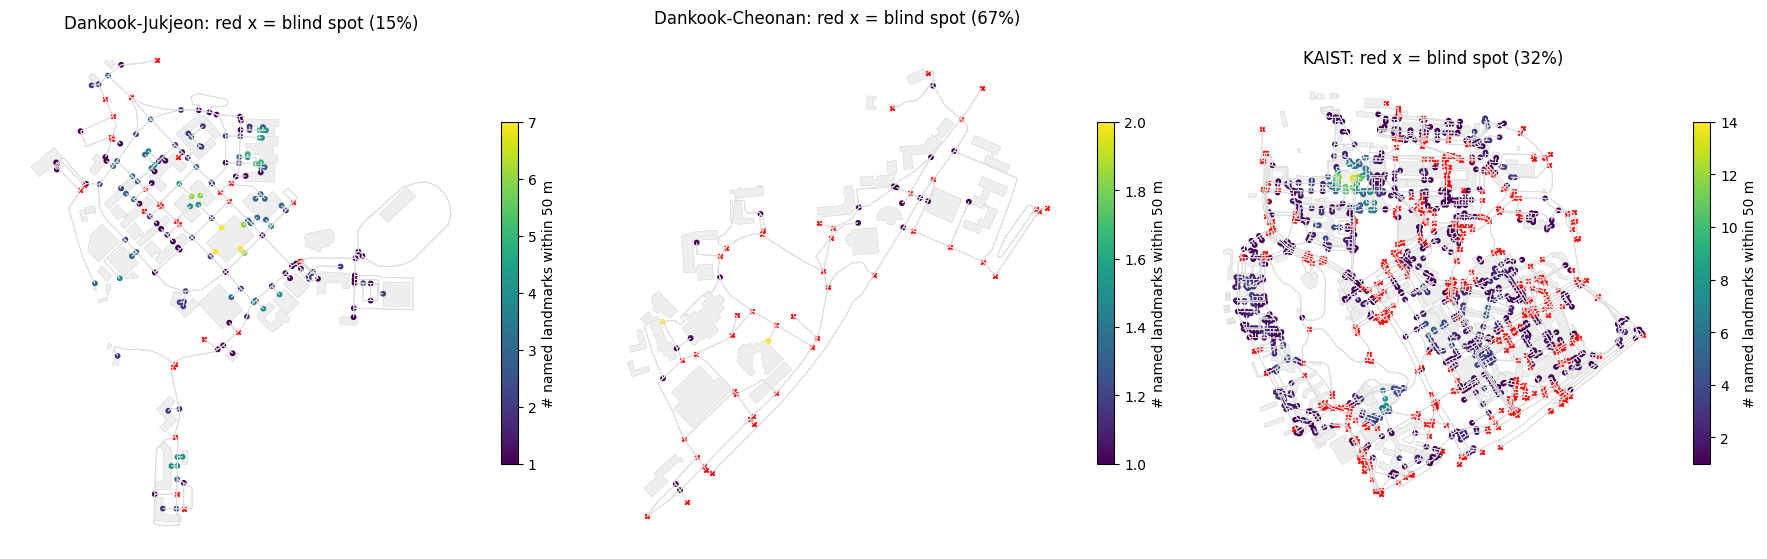

In [8]:
fig, axes = plt.subplots(1, len(data), figsize=(6 * len(data), 6))
for ax, (name, d) in zip(np.atleast_1d(axes), data.items()):
    _, e = ox.graph_to_gdfs(d["G"])
    e.plot(ax=ax, color="#dddddd", lw=0.7)
    if d["buildings"] is not None:
        d["buildings"].plot(ax=ax, color="#eeeeee", edgecolor="#cccccc", lw=0.3)
    n = coverage[name]
    blind = n[n.n_landmarks == 0]
    seen = n[n.n_landmarks > 0]
    seen.plot(ax=ax, column="n_landmarks", cmap="viridis", markersize=10, legend=True,
              legend_kwds={"label": f"# named landmarks within {LANDMARK_RADIUS} m", "shrink": 0.6})
    blind.plot(ax=ax, color="red", markersize=10, marker="x")
    ax.set_title(f"{name}: red x = blind spot ({100*len(blind)/len(n):.0f}%)")
    ax.set_axis_off()
plt.tight_layout(); plt.show()

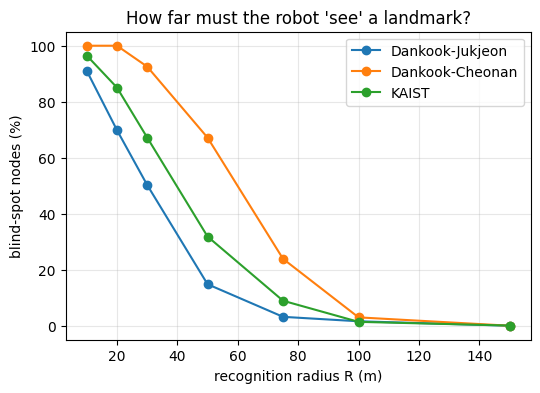

In [9]:
# 반경을 바꾸면 사각지대 비율이 어떻게 변하는가 (센서/카메라 인식 거리의 영향)
radii = [10, 20, 30, 50, 75, 100, 150]
plt.figure(figsize=(6, 4))
for name, d in data.items():
    nodes, _ = ox.graph_to_gdfs(d["G"])
    lm = named_landmarks(d)
    P = np.c_[nodes.geometry.x, nodes.geometry.y]
    L = np.c_[lm.geometry.x, lm.geometry.y]
    dmin = np.linalg.norm(P[:, None] - L[None], axis=2).min(axis=1)  # 가장 가까운 랜드마크 거리
    plt.plot(radii, [100 * (dmin > r).mean() for r in radii], "o-", label=name)
plt.xlabel("recognition radius R (m)"); plt.ylabel("blind-spot nodes (%)")
plt.title("How far must the robot 'see' a landmark?"); plt.grid(alpha=.3); plt.legend()
plt.show()

## 4. 교차로 서술자의 중복성

고유 이웃이 3개 이상인 노드에서 연결 방향의 각도 간격을 30° 단위로 반올림합니다. 순환 순서의 모든 회전 중 사전순 최소를 택한 서술자를 비교합니다.

같은 서술자는 **이 단순 표현으로 구별되지 않는다**는 뜻이며, 다른 관측까지 포함해도 구별할 수 없다는 뜻은 아닙니다. 방향은 노드 간 직선으로 계산하므로 굽은 도로의 교차점 근처 접선과 다를 수 있습니다.

이름 집합 결합 분석은 반경 내 모든 지도 이름을 정확하게 얻는다는 이상적 가정입니다. 결과는 선택한 지도 내부의 서술자 유일성이고 실제 위치추정 정확도가 아닙니다.


In [10]:
def bearing_deg(G, u, v):
    xu, yu = G.nodes[u]["x"], G.nodes[u]["y"]
    xv, yv = G.nodes[v]["x"], G.nodes[v]["y"]
    return math.degrees(math.atan2(yv - yu, xv - xu)) % 360

def descriptor(G, n, step=30):
    nbrs = list(set(G.neighbors(n)))
    if len(nbrs) < 3:
        return None
    b = sorted(bearing_deg(G, n, m) for m in nbrs)
    gaps = [(b[(i + 1) % len(b)] - b[i]) % 360 for i in range(len(b))]
    gaps = [int(round(g / step) * step) for g in gaps]
    # 회전 불변: 원형 순서의 모든 회전 중 사전순 최소
    rots = [tuple(gaps[i:] + gaps[:i]) for i in range(len(gaps))]
    return (len(nbrs), min(rots))

amb_rows = []
for name, d in data.items():
    Gu = ox.convert.to_undirected(d["G"])
    desc = {n: descriptor(Gu, n) for n in Gu.nodes}
    desc = {n: s for n, s in desc.items() if s is not None}
    cnt = Counter(desc.values())
    unique = sum(1 for s in desc.values() if cnt[s] == 1)
    amb_rows.append({
        "campus": name,
        "intersections": len(desc),
        "distinct shapes": len(cnt),
        "uniquely identifiable %": round(100 * unique / max(len(desc), 1), 1),
        "most common shape": str(cnt.most_common(1)[0][0]) if cnt else "-",
        "its count": cnt.most_common(1)[0][1] if cnt else 0,
    })
    d["desc"], d["desc_cnt"] = desc, cnt
pd.DataFrame(amb_rows).set_index("campus")

                 intersections  distinct shapes  uniquely identifiable %  \
campus                                                                     
Dankook-Jukjeon            104               28                     14.4   
Dankook-Cheonan             42               20                     28.6   
KAIST                     1187               93                      3.1   

                  most common shape  its count  
campus                                          
Dankook-Jukjeon  (3, (90, 90, 180))         49  
Dankook-Cheonan  (3, (90, 90, 180))         10  
KAIST            (3, (90, 90, 180))        411  

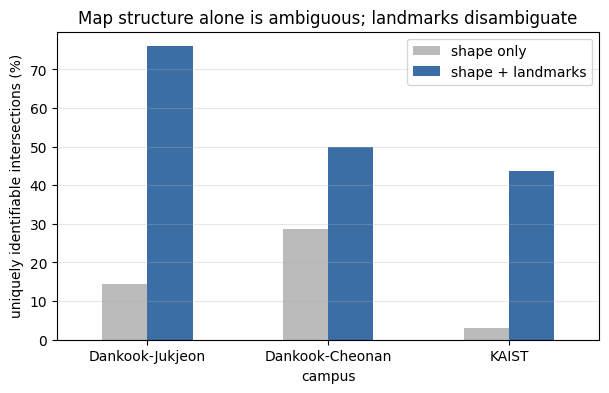

                 shape only  shape + landmarks
campus                                        
Dankook-Jukjeon        14.4               76.0
Dankook-Cheonan        28.6               50.0
KAIST                   3.1               43.7

In [11]:
# 구조 모호성 + 랜드마크를 합치면 얼마나 구별 가능해지는가?
# 교차로 서술자에 '반경 R 안의 랜드마크 이름 집합'을 더한 서술자로 다시 셈
rows = []
for name, d in data.items():
    lm = named_landmarks(d)
    L = np.c_[lm.geometry.x, lm.geometry.y]
    names = lm["name"].values
    Gu = ox.convert.to_undirected(d["G"])
    combo = {}
    for n, s in d["desc"].items():
        p = np.array([Gu.nodes[n]["x"], Gu.nodes[n]["y"]])
        near = names[np.linalg.norm(L - p, axis=1) <= LANDMARK_RADIUS]
        combo[n] = (s, tuple(sorted(set(near))))
    c2 = Counter(combo.values())
    u1 = sum(1 for s in d["desc"].values() if d["desc_cnt"][s] == 1)
    u2 = sum(1 for s in combo.values() if c2[s] == 1)
    N = max(len(combo), 1)
    rows.append({"campus": name, "shape only": 100 * u1 / N, "shape + landmarks": 100 * u2 / N})

df = pd.DataFrame(rows).set_index("campus")
ax = df.plot.bar(figsize=(7, 4), rot=0, color=["#bbbbbb", "#3a6ea5"])
ax.set_ylabel("uniquely identifiable intersections (%)")
ax.set_title("Map structure alone is ambiguous; landmarks disambiguate")
ax.grid(axis="y", alpha=.3); plt.show()
df.round(1)

## 5. 실내 태그 객체 수

현재 쿼리는 `indoor` 태그가 있는 객체를 집계합니다. 객체 수만으로 방·복도 연결 구조나 실내 정보의 완전성을 판단할 수 없습니다. `level`만 가진 객체는 별도 조회가 필요합니다. 실내 위치추정에는 추가 지도 또는 센서 정보가 필요할 수 있으며 건물 도면만이 유일한 방법은 아닙니다.


In [12]:
for name, d in data.items():
    n = 0 if d["indoor"] is None else len(d["indoor"])
    print(f"{name:16s} indoor 객체: {n}개")

Dankook-Jukjeon  indoor 객체: 30개
Dankook-Cheonan  indoor 객체: 0개
KAIST            indoor 객체: 16개


## 6. 탐색 결과와 한계

### 제공된 실행 출력에서 관찰한 내용
- 이름 있는 건물 비율: 죽전 93.3%, 천안 86.4%, KAIST 55.0%.
- 50m 내 이름 있는 대표점이 없는 **노드** 비율: 죽전 14.8%, 천안 67.2%, KAIST 31.8%.
- 형태 서술자의 유일성 → 이름 집합을 더한 유일성: 죽전 14.4% → 76.0%, 천안 28.6% → 50.0%, KAIST 3.1% → 43.7%.
- 선택한 표현과 지도 범위에서 이름 정보가 서술자 중복을 줄였습니다. 실제 위치추정 성능 개선은 검증하지 않았습니다.

### 해석 전 확인할 사항
1. 천안의 검색 경계 27.8ha가 의도한 분석 구역인지 확인해야 합니다. 결과만으로 실제 캠퍼스나 지도 품질의 우열을 단정하지 않습니다.
2. 수집은 경계+30m 버퍼, 면적은 원래 경계 기준입니다. 기존 건물 밀도는 잠정값입니다.
3. 노드 표본은 거리 균등 표본이 아닙니다. 긴 보행로 중간을 평가하려면 보행로 길이 기준 표본이 필요합니다.
4. 기본 통계는 그래프 degree, 모호성 분석은 고유 이웃 수를 사용합니다. 죽전 117/104처럼 교차로 수가 달라지므로 직접 혼용하지 않습니다.
5. 동일 이름의 객체, 건물-POI 중복, 대표점과 관측 가능한 간판의 차이를 검토해야 합니다.
6. 50m와 30°는 분석 설정이며 센서 성능에서 검증된 값이 아닙니다.
7. 수집 날짜와 경계 ID가 기록되지 않았고 OSM은 갱신됩니다. 재실행 결과는 달라질 수 있습니다.

### 다음 단계 (미구현)
- 경계 ID 고정 및 지도 위 수동 확인
- 버퍼 수집과 내부 평가 범위 분리
- 보행로 10m 간격 평가 및 반경 20/50/100m 비교
- 각도 양자화 15/30/45° 민감도 비교
- 이름 누락 모의실험과 실제 현장 관측 검증

기존 결론의 55/73/84m 임계거리 및 모든 실내 태그가 indoor=yes라는 주장은 계산·집계 근거가 부족하여 제외했습니다.
